# Kenya monetary policy transmission — reproduction notebook
Samuel Ndungu Njoroge | 2016–2026

This notebook reproduces the canonical research engine in seven sequential stages. Run from repository root or in Colab. It uses a fixed real-data snapshot. Outputs are generated when run; published results are in [the paper](../RESEARCH_PAPER.md) and the successful workflow artifact. No simulated data.

In [1]:
import sys, subprocess, os
from pathlib import Path
if not Path('data/processed/kenya_monetary_policy_audited.csv').exists() and Path('../data/processed/kenya_monetary_policy_audited.csv').exists():
    os.chdir('..')
if not Path('data/processed/kenya_monetary_policy_audited.csv').exists():
    repo=Path('kenya-monetary-policy-analysis')
    if not repo.exists():
        subprocess.run(['git','clone','https://github.com/samuel6183/kenya-monetary-policy-analysis.git',str(repo)],check=True)
    os.chdir(repo)
# Run with the dependency versions listed in the paper for exact reproduction.


In [2]:
"""Canonical dataset analysis; reproducible retrospective evaluation."""
import argparse, hashlib, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller,kpss
from statsmodels.tsa.api import VAR
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
HASH="444a98058e22f669b103385227511d0f149e39b9644f5b0f40df6fffbd2c714e"
CORE=["CENTRAL_BANK_RATE","LENDING","INFLATION_YOY"]

from IPython.display import display, SVG
path='data/processed/kenya_monetary_policy_audited.csv'
output='outputs/notebook'


## 1. Load the exact canonical snapshot, verify its checksum and initialize output folders.

In [3]:
assert hashlib.sha256(Path(path).read_bytes()).hexdigest()==HASH
d=pd.read_csv(path); d.index=pd.PeriodIndex(d.pop("DATE"),freq="M")
assert d.index.equals(pd.period_range("2016-11","2026-09",freq="M"))
assert d[CORE].notna().all().all()
n=d.select_dtypes("number"); t=Path(output)/"tables"; f=Path(output)/"figures"
t.mkdir(parents=True,exist_ok=True); f.mkdir(parents=True,exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(f/(name+".svg"),bbox_inches="tight"); plt.close("all")
def plot(cols,name,title):
    ax=n[cols].to_timestamp().plot(figsize=(10,4),grid=True,title=title); ax.set_ylabel("Percent"); save(name)
display(d.head())
print(d.isna().sum())

,CENTRAL_BANK_RATE,INTERBANK_RATE,CASH_RESERVE_REQUIREMENT,91_DAY_TBILL,182_DAYS_TBILL,364_DAYS_TBILL,DEPOSIT,SAVINGS,LENDING,OVERDRAFT,REPO,REVERSE_REPO,INFLATION_YOY,KENYA_CPI,CPI_BASE
DATE,,,,,,,,,,,,,,,
2016-11,10.0,5.11,5.25,8.22,10.32,10.74,7.65,6.52,13.67,13.49,7.05,10.17,6.68,173.85,February 2009=100
2016-12,10.0,5.92,5.25,8.44,10.55,11.02,7.33,6.37,13.66,13.49,NaN,10.04,6.35,175.18,February 2009=100
2017-01,10.0,7.70,5.25,8.58,10.50,10.98,7.20,6.09,13.66,13.30,9.95,10.02,6.99,176.93,February 2009=100
2017-02,10.0,6.41,5.25,8.64,10.53,10.93,7.65,6.81,13.69,13.32,9.88,10.01,9.04,179.98,February 2009=100
2017-03,10.0,4.46,5.25,8.69,10.53,10.91,7.12,5.89,13.61,13.29,7.23,10.04,10.28,182.98,February 2009=100


CENTRAL_BANK_RATE            0
INTERBANK_RATE               0
CASH_RESERVE_REQUIREMENT     0
91_DAY_TBILL                 0
182_DAYS_TBILL               1
364_DAYS_TBILL               0
DEPOSIT                      0
SAVINGS                      0
LENDING                      0
OVERDRAFT                    0
REPO                        32
REVERSE_REPO                41
INFLATION_YOY                0
KENYA_CPI                    0
CPI_BASE                     0
dtype: int64


## 2. Plot every historical indicator; preserve missing values and split CPI by base.

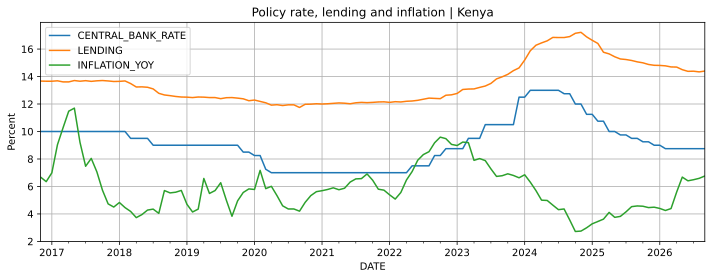

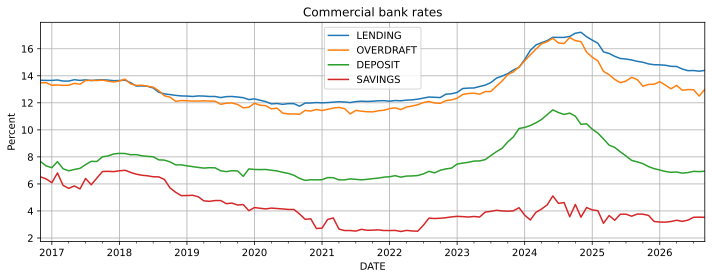

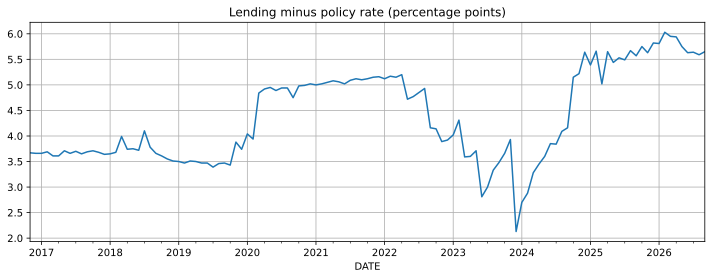

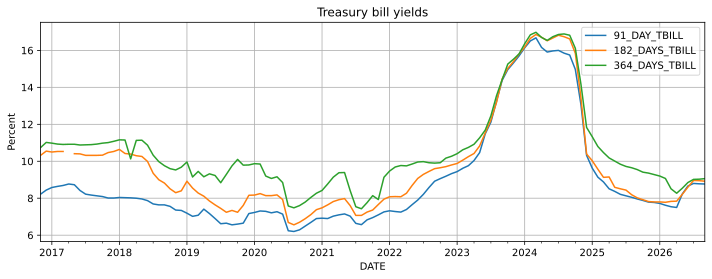

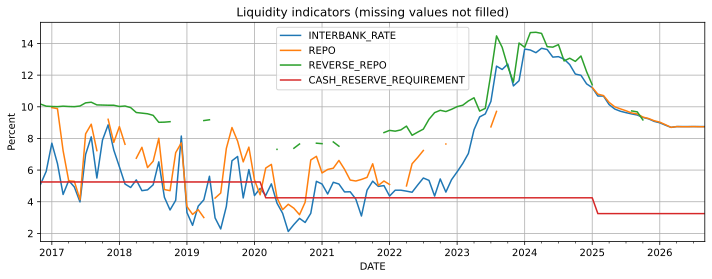

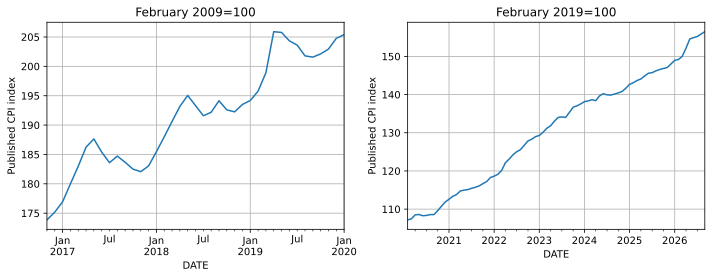

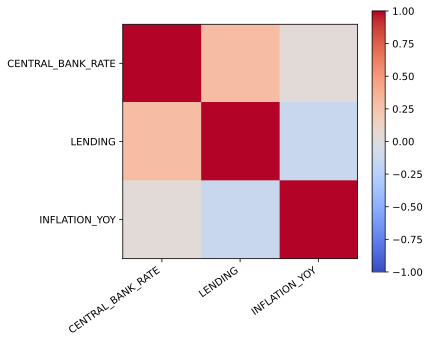

In [4]:
plot(CORE,"policy_transmission","Policy rate, lending and inflation | Kenya")
plot(["91_DAY_TBILL","182_DAYS_TBILL","364_DAYS_TBILL"],"treasury_yields","Treasury bill yields")
plot(["INTERBANK_RATE","REPO","REVERSE_REPO","CASH_RESERVE_REQUIREMENT"],"liquidity","Liquidity indicators (missing values not filled)")
plot(["LENDING","OVERDRAFT","DEPOSIT","SAVINGS"],"bank_rates","Commercial bank rates")
(n.LENDING-n.CENTRAL_BANK_RATE).to_timestamp().plot(figsize=(10,4),title="Lending minus policy rate (percentage points)",grid=True); save("lending_spread")
fig,axes=plt.subplots(1,2,figsize=(10,4))
for (base,g),ax in zip(d.groupby("CPI_BASE",sort=False),axes):
    g.KENYA_CPI.to_timestamp().plot(ax=ax,title=base,grid=True); ax.set_ylabel("Published CPI index")
save("cpi_by_base")
n.describe().T.to_csv(t/"descriptive.csv"); n.isna().sum().to_csv(t/"missing.csv",header=["missing"]); n.drop(columns="KENYA_CPI").corr().to_csv(t/"level_correlations.csv")
corr=n[CORE].diff().corr(); fig,ax=plt.subplots(figsize=(6,5)); im=ax.imshow(corr,vmin=-1,vmax=1,cmap="coolwarm"); ax.set_xticks(range(3),CORE,rotation=35,ha="right"); ax.set_yticks(range(3),CORE); fig.colorbar(im); save("change_correlations")
for name in ['policy_transmission','bank_rates','lending_spread','treasury_yields','liquidity','cpi_by_base','change_correlations']:
    display(SVG(filename=str(f/(name+'.svg'))))

## 3. Assess stationarity in levels and first differences. ADF and KPSS have different null hypotheses.

In [5]:
tests=[]
for c in CORE:
    for form,s in [("level",n[c]),("difference",n[c].diff().dropna())]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore"); a=adfuller(s,autolag="AIC"); k=kpss(s,regression="c",nlags="auto")
        tests.append(dict(variable=c,form=form,ADF_stat=a[0],ADF_p=a[1],KPSS_stat=k[0],KPSS_p_bound=k[1]))
pd.DataFrame(tests).to_csv(t/"stationarity.csv",index=False)
display(pd.read_csv(t/'stationarity.csv'))

,variable,form,ADF_stat,ADF_p,KPSS_stat,KPSS_p_bound
0,CENTRAL_BANK_RATE,level,-2.202641,0.205288,0.348080,0.099534
1,CENTRAL_BANK_RATE,difference,-2.452185,0.127546,0.182051,0.100000
2,LENDING,level,-1.724915,0.418323,0.830760,0.010000
3,LENDING,difference,-2.834724,0.053482,0.209379,0.100000
4,INFLATION_YOY,level,-2.096287,0.246010,0.173211,0.100000
5,INFLATION_YOY,difference,-3.708947,0.003989,0.054682,0.100000


## 4. Estimate dynamic OLS regressions with HAC covariance and check residual autocorrelation.

In [6]:
z=n[CORE].diff().rename(columns={c:"d_"+c for c in CORE}).dropna()
reg=[]
for target in ["d_LENDING","d_INFLATION_YOY"]:
    x=z.shift(1).dropna(); y=z.loc[x.index,target]; fit=sm.OLS(y,sm.add_constant(x)).fit(cov_type="HAC",cov_kwds={"maxlags":6})
    for term in fit.params.index:
        reg.append(dict(target=target,term=term,coef=fit.params[term],se=fit.bse[term],p=fit.pvalues[term],lo=fit.conf_int().loc[term,0],hi=fit.conf_int().loc[term,1],n=int(fit.nobs),r2=fit.rsquared))
    (t/(target+"_summary.txt")).write_text(fit.summary().as_text()); acorr_ljungbox(fit.resid,lags=[6,12],return_df=True).to_csv(t/(target+"_ljungbox.csv"))
pd.DataFrame(reg).to_csv(t/"regression.csv",index=False)
display(pd.read_csv(t/'regression.csv'))
display(pd.read_csv(t/'d_LENDING_ljungbox.csv'))
display(pd.read_csv(t/'d_INFLATION_YOY_ljungbox.csv'))

,target,term,coef,se,p,lo,hi,n,r2
0,d_LENDING,const,0.005315,0.008845,5.478923e-01,-0.012021,0.022652,117,0.488522
1,d_LENDING,d_CENTRAL_BANK_RATE,0.177779,0.033561,1.175562e-07,0.112002,0.243557,117,0.488522
2,d_LENDING,d_LENDING,0.506011,0.101878,6.804823e-07,0.306335,0.705688,117,0.488522
3,d_LENDING,d_INFLATION_YOY,-0.014469,0.010963,1.868991e-01,-0.035956,0.007018,117,0.488522
4,d_INFLATION_YOY,const,0.007192,0.057484,9.004322e-01,-0.105474,0.119858,117,0.071762
5,d_INFLATION_YOY,d_CENTRAL_BANK_RATE,-0.008322,0.181917,9.635147e-01,-0.364873,0.348230,117,0.071762
6,d_INFLATION_YOY,d_LENDING,-0.631811,0.257935,1.430570e-02,-1.137355,-0.126267,117,0.071762
7,d_INFLATION_YOY,d_INFLATION_YOY,0.206229,0.125583,1.005530e-01,-0.039908,0.452367,117,0.071762


,Unnamed: 0,lb_stat,lb_pvalue
0,6,19.021781,0.004127
1,12,29.420679,0.003411


,Unnamed: 0,lb_stat,lb_pvalue
0,6,9.426611,0.150969
1,12,20.594460,0.056644


## 5. Fit the reduced-form VAR, choose lag order and assess stability, whiteness and normality.

{'bic_selected': 1, 'fitted_lag': 1, 'n': 117, 'stable': True, 'whiteness_p': 0.0005313714986816292, 'normality_p': 1.9314915421497608e-255, 'max_companion_eigenvalue': 0.6911984806110183}


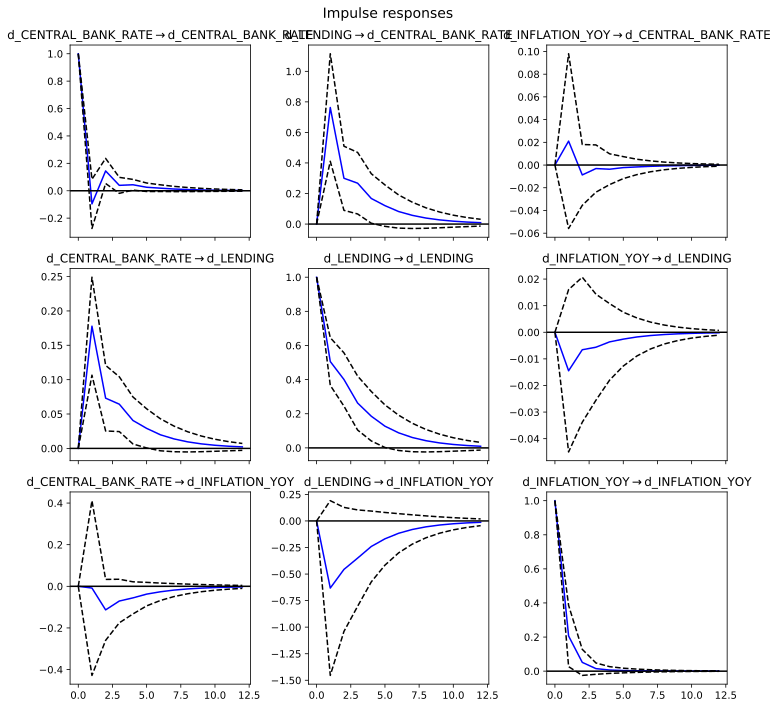

In [7]:
model=VAR(z.to_timestamp()); selection=model.select_order(6); order=int(selection.selected_orders["bic"]); lag=max(1,order); fit=model.fit(lag)
pd.DataFrame(selection.ics).rename_axis("lag").to_csv(t/"var_lag_selection.csv")
fit.params.to_csv(t/"var_coefficients.csv"); fit.pvalues.to_csv(t/"var_pvalues.csv"); (t/"var_summary.txt").write_text(str(fit.summary()))
white=fit.test_whiteness(nlags=12,adjusted=True); normal=fit.test_normality(); stable=bool(fit.is_stable())
diag=dict(bic_selected=order,fitted_lag=lag,n=int(fit.nobs),stable=stable,whiteness_p=float(white.pvalue),normality_p=float(normal.pvalue),max_companion_eigenvalue=float(1/min(abs(fit.roots))))
(t/"var_diagnostics.json").write_text(json.dumps(diag,indent=2))
if stable:
    fit.irf(12).plot(orth=False,plot_stderr=True,signif=.05); save("var_impulse_responses")
print(diag)
if stable:
    display(SVG(filename=str(f/'var_impulse_responses.svg')))

## 6. Evaluate fixed forecasting models with expanding-window one-step predictions. No future observation enters a training window.

,model,MAE,RMSE,bias
4,VAR2,0.270426,0.394003,-0.055438
3,ARIMA110,0.283194,0.394461,-0.112205
2,AR1,0.269199,0.419903,-0.043256
0,persistence,0.285833,0.425451,-0.133333
1,seasonal_naive,1.917083,2.232500,0.041250


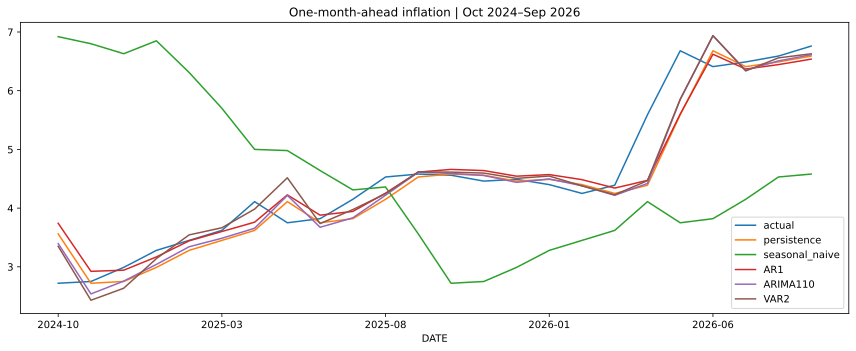

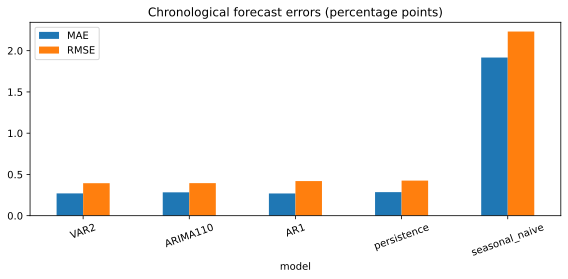

In [8]:
rows=[]; y=n.INFLATION_YOY
for i in range(len(y)-24,len(y)):
    train=y.iloc[:i].to_numpy(); ar=sm.OLS(train[1:],sm.add_constant(train[:-1],has_constant="add")).fit()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); arima=ARIMA(train,order=(1,1,0)).fit()
    vtrain=z.loc[z.index<y.index[i]]; vfit=VAR(vtrain.to_timestamp()).fit(2); vp=vfit.forecast(vtrain.to_numpy()[-2:],1)[0,2]+train[-1]
    rows.append(dict(DATE=str(y.index[i]),actual=y.iloc[i],persistence=train[-1],seasonal_naive=train[-12],AR1=ar.params[0]+ar.params[1]*train[-1],ARIMA110=float(arima.forecast()[0]),VAR2=vp,arima_converged=bool(arima.mle_retvals.get("converged",False))))
pred=pd.DataFrame(rows); pred.to_csv(t/"forecast_holdout.csv",index=False); scores=[]
for c in ["persistence","seasonal_naive","AR1","ARIMA110","VAR2"]:
    e=pred[c]-pred.actual; scores.append(dict(model=c,MAE=float(e.abs().mean()),RMSE=float(np.sqrt((e**2).mean())),bias=float(e.mean())))
scores=pd.DataFrame(scores).sort_values("RMSE"); scores.to_csv(t/"forecast_metrics.csv",index=False)
pred.set_index("DATE").drop(columns="arima_converged").plot(figsize=(12,5),title="One-month-ahead inflation | Oct 2024–Sep 2026"); save("forecast_holdout")
scores.set_index("model")[["MAE","RMSE"]].plot.bar(figsize=(8,4),rot=20,title="Chronological forecast errors (percentage points)"); save("forecast_comparison")
display(scores)
display(SVG(filename=str(f/'forecast_holdout.svg')))
display(SVG(filename=str(f/'forecast_comparison.svg')))

## 7. Record the execution manifest.

In [9]:
report={"sha256":HASH,"months":len(d),"var":diag,"forecast":scores.to_dict("records"),"arima_nonconverged":int((~pred.arima_converged).sum())}
(t/"run.json").write_text(json.dumps(report,indent=2)); print(json.dumps(report,indent=2))
print('Outputs:',output)

{
  "sha256": "444a98058e22f669b103385227511d0f149e39b9644f5b0f40df6fffbd2c714e",
  "months": 119,
  "var": {
    "bic_selected": 1,
    "fitted_lag": 1,
    "n": 117,
    "stable": true,
    "whiteness_p": 0.0005313714986816292,
    "normality_p": 1.9314915421497608e-255,
    "max_companion_eigenvalue": 0.6911984806110183
  },
  "forecast": [
    {
      "model": "VAR2",
      "MAE": 0.270425656292207,
      "RMSE": 0.3940034568493269,
      "bias": -0.05543843690879019
    },
    {
      "model": "ARIMA110",
      "MAE": 0.28319416096601596,
      "RMSE": 0.39446076492710946,
      "bias": -0.11220458101650044
    },
    {
      "model": "AR1",
      "MAE": 0.26919878439150774,
      "RMSE": 0.4199025776419368,
      "bias": -0.04325586852176646
    },
    {
      "model": "persistence",
      "MAE": 0.28583333333333333,
      "RMSE": 0.4254507413712348,
      "bias": -0.13333333333333333
    },
    {
      "model": "seasonal_naive",
      "MAE": 1.917083333333333,
      "RMSE": 2.23

## Interpretation
The published lending coefficient is positive, but residual autocorrelation remains. VAR stability does not imply valid residual diagnostics. Forecast ranking differs by error metric. Results are retrospective and associative, not causal. CPI base periods must remain separate. See the paper for limitations and references.